In [8]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv

In [4]:
load_dotenv()

True

In [24]:
model = ChatOpenAI(model_name="gpt-4.1-nano", temperature=0.2)

In [25]:
# create a state

class LLMState(TypedDict):
    question: str
    answer: str

In [26]:
def llmQA(state: LLMState) -> LLMState:
    #extract the question from state
    question = state['question']
    # form a prompt
    prompt = f'Answer the following question {question}'
    # ask that question to the LLM
    answer = model.invoke(prompt).content
    #update the answer in the state
    state['answer'] = answer

    return state

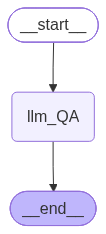

In [27]:
# Create our graph

graph = StateGraph(LLMState)

# add nodes
graph.add_node('llm_QA', llmQA)

# add edges

graph.add_edge(START, 'llm_QA')
graph.add_edge('llm_QA', END)


# compile
graph.compile()

In [28]:
workflow = graph.compile()

In [29]:
# Execute
initialState = {'question' : 'How far is moon from the Earth?'}

finalState = workflow.invoke(initialState)

print(finalState)

{'question': 'How far is moon from the Earth?', 'answer': "The average distance from the Moon to the Earth is approximately 384,400 kilometers (about 238,855 miles). This distance can vary slightly due to the Moon's elliptical orbit around the Earth."}
